# SentinelAI — Threat Intelligence Exploration
## Step 1: In-Depth Exploration of MITRE ATT&CK Enterprise Matrix

### Objective
This notebook performs a deep exploratory analysis of the **MITRE ATT&CK Enterprise Matrix** formatted in STIX 2.1 JSON.
We examine the schema, quantify object types, inspect three representative attack techniques, and determine how techniques, mitigations, detection guidance, and relationships are stored for downstream Retrieval-Augmented Generation (RAG).


---
### Task 1: Load the JSON Dataset
We load `enterprise-attack.json` from the raw data repository and confirm that it loads successfully into memory.


In [1]:
import os
import sys
import json
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 120)

# Resolve path
DATA_PATH = os.path.abspath("../data/raw/mitre_attack/enterprise-attack.json")
if not os.path.exists(DATA_PATH):
    # Fallback if run from workspace root
    DATA_PATH = os.path.abspath("intelligence/data/raw/mitre_attack/enterprise-attack.json")

print(f"Loading MITRE ATT&CK from: {DATA_PATH}")
assert os.path.exists(DATA_PATH), f"File not found: {DATA_PATH}"

with open(DATA_PATH, "r", encoding="utf-8") as f:
    mitre_data = json.load(f)

file_size_mb = os.path.getsize(DATA_PATH) / (1024 * 1024)
print(f"[SUCCESS] Loaded enterprise-attack.json successfully ({file_size_mb:.2f} MB)")


Loading MITRE ATT&CK from: C:\Users\himma\Desktop\Projects\AI project\SentinelAI\intelligence\data\raw\mitre_attack\enterprise-attack.json


[SUCCESS] Loaded enterprise-attack.json successfully (52.71 MB)


---
### Task 2: Understand the Overall Structure
Inspect top-level keys and determine how STIX objects are stored within the bundle.


In [2]:
print("Top-level keys in dataset:", list(mitre_data.keys()))
print(f"STIX Bundle Type:    {mitre_data.get('type')}")
print(f"STIX Bundle ID:      {mitre_data.get('id')}")

objects = mitre_data.get("objects", [])
print(f"Total STIX objects:  {len(objects):,}")

# Inspect the structure of the first 2 objects
print("\nFirst Object Sample (Type & ID):")
print(f"  • Type: {objects[0].get('type')} | ID: {objects[0].get('id')}")
print(f"  • Available Keys: {list(objects[0].keys())}")


Top-level keys in dataset: ['type', 'id', 'objects']
STIX Bundle Type:    bundle
STIX Bundle ID:      bundle--fc207382-c9d1-4ece-bce2-6ef555c62d0a
Total STIX objects:  26,690

First Object Sample (Type & ID):
  • Type: x-mitre-collection | ID: x-mitre-collection--1f5f1533-f617-4ca8-9ab4-6a02367fa019
  • Available Keys: ['type', 'id', 'x_mitre_attack_spec_version', 'name', 'x_mitre_version', 'description', 'created_by_ref', 'created', 'modified', 'x_mitre_contents', 'object_marking_refs', 'spec_version']


---
### Task 3: Count Object Types
Count all STIX objects (such as `attack-pattern`, `malware`, `tool`, `intrusion-set`, `relationship`, `course-of-action`, `x-mitre-analytic`, etc.) and summarize the distribution.


,STIX Object Type,Record Count,Percentage
0,relationship,21819,81.75%
1,x-mitre-analytic,1770,6.63%
2,attack-pattern,867,3.25%
3,malware,750,2.81%
4,x-mitre-detection-strategy,705,2.64%
5,course-of-action,268,1.00%
6,intrusion-set,193,0.72%
7,x-mitre-data-component,109,0.41%
8,tool,95,0.36%
9,campaign,57,0.21%


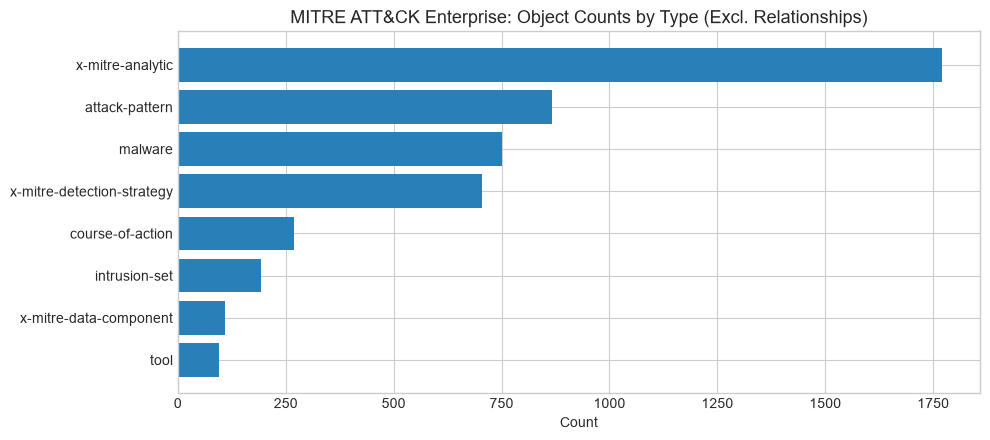

In [3]:
type_counts = Counter(obj.get("type", "unknown") for obj in objects)

type_summary = []
for obj_type, count in type_counts.most_common():
    type_summary.append({
        "STIX Object Type": obj_type,
        "Record Count": count,
        "Percentage": f"{(count / len(objects)) * 100:.2f}%"
    })

type_df = pd.DataFrame(type_summary)
display(type_df)

# Visualize primary threat objects (excluding relationship graph edges)
plt.figure(figsize=(10, 4.5))
non_rel = type_df[type_df["STIX Object Type"] != "relationship"].head(8)
plt.barh(non_rel["STIX Object Type"][::-1], non_rel["Record Count"][::-1], color="#2980b9")
plt.title("MITRE ATT&CK Enterprise: Object Counts by Type (Excl. Relationships)", fontsize=13)
plt.xlabel("Count")
plt.tight_layout()
plt.show()


---
### Task 4: Inspect Three Attack Techniques
Examine names, technique IDs, descriptions, detection guidance, mitigation information, and external references for three representative techniques:
1. **`T1059`** — Command and Scripting Interpreter (Execution)
2. **`T1021.002`** — Remote Services: SMB/Windows Admin Shares (Lateral Movement)
3. **`T1110`** — Brute Force (Credential Access)

We also resolve and display the **linked mitigations** and **detection analytics** connected via STIX relationships.


In [4]:
# Helper lookup dictionaries
id_to_object = {obj["id"]: obj for obj in objects if "id" in obj}
relationships = [obj for obj in objects if obj.get("type") == "relationship"]

def get_mitre_id(obj):
    for ref in obj.get("external_references", []):
        if ref.get("source_name") == "mitre-attack":
            return ref.get("external_id")
    return "N/A"

# Index techniques by MITRE external ID
techniques_by_mitre_id = {}
for obj in objects:
    if obj.get("type") == "attack-pattern" and not obj.get("revoked", False):
        mid = get_mitre_id(obj)
        if mid != "N/A":
            techniques_by_mitre_id[mid] = obj

# Index mitigates relationships by target technique
mitigates_by_target = {}
for rel in relationships:
    if rel.get("relationship_type") == "mitigates":
        target = rel.get("target_ref")
        mitigates_by_target.setdefault(target, []).append(rel)

# Index detects relationships by target technique
detects_by_target = {}
for rel in relationships:
    if rel.get("relationship_type") == "detects":
        target = rel.get("target_ref")
        detects_by_target.setdefault(target, []).append(rel)

target_ids = ["T1059", "T1021.002", "T1110"]

for tid in target_ids:
    tech = techniques_by_mitre_id.get(tid)
    if not tech:
        print(f"[!] Technique {tid} not found!")
        continue
        
    stix_id = tech["id"]
    name = tech.get("name")
    is_sub = tech.get("x_mitre_is_subtechnique", False)
    platforms = tech.get("x_mitre_platforms", [])
    tactics = [kc.get("phase_name") for kc in tech.get("kill_chain_phases", []) if kc.get("kill_chain_name") == "mitre-attack"]
    desc = tech.get("description", "")
    ext_refs = tech.get("external_references", [])
    
    print("=" * 90)
    print(f"TECHNIQUE: [{tid}] {name}")
    print("=" * 90)
    print(f"• STIX ID:            {stix_id}")
    print(f"• Sub-Technique:      {is_sub}")
    print(f"• Kill Chain Tactics: {', '.join(tactics)}")
    print(f"• Platforms:          {', '.join(platforms)}")
    print(f"\n• Description Preview:\n{desc[:300].strip()}...\n")
    
    # External References
    print(f"• External References ({len(ext_refs)} citations):")
    for ref in ext_refs[:3]:
        print(f"   - [{ref.get('source_name')}]: {ref.get('url', 'No URL')} (External ID: {ref.get('external_id', 'None')})")
        
    # Detection Guidance (Resolved from detects relationships)
    det_rels = detects_by_target.get(stix_id, [])
    print(f"\n• Detection Guidance ({len(det_rels)} linked detection strategies/analytics):")
    if det_rels:
        for d_rel in det_rels[:2]:
            source_obj = id_to_object.get(d_rel.get("source_ref"))
            if source_obj:
                s_name = source_obj.get("name", "Unnamed Strategy")
                s_desc = source_obj.get("description", "")
                print(f"   * [{source_obj.get('type')}]: {s_name}")
                if s_desc:
                    print(f"     Guidance: {s_desc[:250].strip()}...")
    else:
        print("   * Detection guidance is detailed in high-level data components or parent technique.")

    # Mitigation Information (Resolved from mitigates relationships)
    mit_rels = mitigates_by_target.get(stix_id, [])
    print(f"\n• Linked Mitigations ({len(mit_rels)} linked defensive courses of action):")
    if mit_rels:
        for m_rel in mit_rels[:3]:
            mit_obj = id_to_object.get(m_rel.get("source_ref"))
            if mit_obj:
                m_code = get_mitre_id(mit_obj)
                m_name = mit_obj.get("name", "Unknown Mitigation")
                specific_guidance = m_rel.get("description", mit_obj.get("description", ""))
                print(f"   * [{m_code}] {m_name}")
                print(f"     Specific Application: {specific_guidance[:200].strip()}...")
    else:
        print("   * No direct course-of-action relationships linked.")
    print("\n")


TECHNIQUE: [T1059] Command and Scripting Interpreter
• STIX ID:            attack-pattern--7385dfaf-6886-4229-9ecd-6fd678040830
• Sub-Technique:      False
• Kill Chain Tactics: execution
• Platforms:          Containers, ESXi, IaaS, Identity Provider, Linux, macOS, Network Devices, Office Suite, SaaS, Windows

• Description Preview:
Adversaries may abuse command and script interpreters to execute commands, scripts, or binaries. These interfaces and languages provide ways of interacting with computer systems and are a common feature across many different platforms. Most systems come with some built-in command-line interface and...

• External References (4 citations):
   - [mitre-attack]: https://attack.mitre.org/techniques/T1059 (External ID: T1059)
   - [Remote Shell Execution in Python]: https://www.thepythoncode.com/article/executing-bash-commands-remotely-in-python (External ID: None)
   - [Cisco IOS Software Integrity Assurance - Command History]: https://tools.cisco.com/security

---
### Task 5: Observations & RAG Extraction Strategy

#### 5.1 Analysis of Fields for Cybersecurity Q&A:
1. **Directly Usable Fields in `attack-pattern`**:
   * `name`: Technique title (e.g. *Command and Scripting Interpreter*).
   * `external_references` (`source_name == "mitre-attack"`): MITRE Technique code (e.g. `T1059`).
   * `description`: Comprehensive technical explanation of adversary methodology.
   * `kill_chain_phases`: Specific stage in attack lifecycle (e.g. `execution`, `lateral-movement`).
   * `x_mitre_platforms`: Targeted operating systems and execution environments.
   * `x_mitre_is_subtechnique`: Hierarchical indicator.

2. **Fields Requiring Graph Traversal (Linked Records)**:
   * **Mitigations**: Mitigations are **not** inline strings in `attack-pattern`. They are separate `course-of-action` objects (e.g. `M1031`) joined via `relationship` objects where `relationship_type == "mitigates"`. Crucially, the technique-specific implementation advice resides in `relationship["description"]`.
   * **Detection Guidance**: In modern ATT&CK STIX 2.1, detection guidance has been decoupled from `x_mitre_detection` into dedicated `x-mitre-detection-strategy` and `x-mitre-analytic` objects linked via `detects` relationships.
   * **Threat Groups & Malware**: Adversaries abusing this technique are linked via `uses` relationships from `intrusion-set` (e.g. APT29) and `malware` (e.g. Cobalt Strike).
   * **Parent-Child Hierarchy**: Sub-techniques point to their parent technique via `subtechnique-of` relationships.

---

### Step 4: Summary Table Across Knowledge Sources

| Source | Record Count | Useful Fields | Observations |
| :--- | :--- | :--- | :--- |
| **MITRE ATT&CK** | **$26,690$ STIX Objects**<br>($867$ techniques, $750$ malware, $268$ mitigations, $21,819$ relationships) | `external_id`, `name`, `description`, `kill_chain_phases`, `x_mitre_platforms`, `mitigates` rels, `detects` rels | Graph bundle. Mitigations and detection analytics are separate objects linked via relationships rather than inline fields. |
| **CISA KEV** | *To determine* | CVE IDs, products, descriptions, dates | Structured vulnerability records |
| **NVD** | *To determine* | CVE IDs, descriptions, severity | Initial sample only |
| **OWASP** | *To determine* | Category, description, guidance | Markdown documents |


In [5]:
# Summary Verification Printout
print("=" * 80)
print("  STEP 1 — MITRE ATT&CK EXPLORATION COMPLETED")
print("=" * 80)
print(f"• Total STIX Objects Ingested:    {len(objects):,}")
print(f"• Active Attack Patterns:        {len(techniques_by_mitre_id):,}")
print(f"• Total Graph Relationships:     {len(relationships):,}")
print(f"• Mitigation Relationships:      {len(mitigates_by_target):,} targeted techniques")
print(f"• Detection Analytics Linked:    {len(detects_by_target):,} targeted techniques")
print("=" * 80)


  STEP 1 — MITRE ATT&CK EXPLORATION COMPLETED
• Total STIX Objects Ingested:    26,690
• Active Attack Patterns:        718
• Total Graph Relationships:     21,819
• Mitigation Relationships:      595 targeted techniques
• Detection Analytics Linked:    703 targeted techniques


---
# Step 2: In-Depth Exploration of CISA Known Exploited Vulnerabilities (KEV)

### Objective
Explore the official CISA KEV catalog (`known_exploited_vulnerabilities.json`) to understand:
1. JSON structure and record storage
2. Key fields per vulnerability
3. Data quality (missing values, duplicate CVEs, vendor/product distributions)
4. RAG mapping (Searchable text embeddings vs. structured metadata filters)


In [6]:
# 1. Dataset Structure & Loading
CISA_PATH = os.path.abspath("../data/raw/cisa/known_exploited_vulnerabilities.json")
if not os.path.exists(CISA_PATH):
    CISA_PATH = os.path.abspath("intelligence/data/raw/cisa/known_exploited_vulnerabilities.json")

with open(CISA_PATH, "r", encoding="utf-8") as f:
    cisa_data = json.load(f)

print("Top-level JSON keys:", list(cisa_data.keys()))
print(f"• Title:           {cisa_data.get('title')}")
print(f"• Catalog Version: {cisa_data.get('catalogVersion')}")
print(f"• Date Released:   {cisa_data.get('dateReleased')}")
print(f"• Metadata Count:  {cisa_data.get('count'):,}")

cisa_vulns = cisa_data.get("vulnerabilities", [])
print(f"• Stored Records:  {len(cisa_vulns):,} vulnerabilities inside 'vulnerabilities' array")


Top-level JSON keys: ['title', 'catalogVersion', 'dateReleased', 'count', 'vulnerabilities']
• Title:           CISA Catalog of Known Exploited Vulnerabilities
• Catalog Version: 2026.10.13
• Date Released:   2026-10-13T19:10:43.6568Z
• Metadata Count:  1,741
• Stored Records:  1,741 vulnerabilities inside 'vulnerabilities' array


In [7]:
# 2. Field Inspection Across 4 Representative Records
print(f"Total fields per record: {len(cisa_vulns[0].keys())}")
print("Fields:", list(cisa_vulns[0].keys()))

sample_cves = ["CVE-2026-104935", "CVE-2026-96951", "CVE-2015-5477", "CVE-2016-3081"]
inspected_samples = [v for v in cisa_vulns if v.get("cveID") in sample_cves]

for i, vuln in enumerate(inspected_samples):
    print("=" * 80)
    print(f"RECORD {i+1}: {vuln.get('cveID')} - {vuln.get('vulnerabilityName')}")
    print("=" * 80)
    print(f"• Vendor / Project:    {vuln.get('vendorProject')}")
    print(f"• Affected Product:    {vuln.get('product')}")
    print(f"• Date Added:          {vuln.get('dateAdded')} (Remediation Due: {vuln.get('dueDate')})")
    print(f"• Ransomware Status:   {vuln.get('knownRansomwareCampaignUse')}")
    print(f"• Weakness (CWE):      {', '.join(vuln.get('cwes', []))}")
    print(f"\n• Description Preview:\n  {vuln.get('shortDescription')[:200]}...")
    print(f"\n• Required Action:\n  {vuln.get('requiredAction')[:200]}...")
    print()


Total fields per record: 12
Fields: ['cveID', 'vendorProject', 'product', 'vulnerabilityName', 'dateAdded', 'shortDescription', 'requiredAction', 'dueDate', 'knownRansomwareCampaignUse', 'forensicTriage', 'notes', 'cwes']
RECORD 1: CVE-2026-104935 - Ivanti Connect Secure Authentication Bypass by Spoofing Vulnerability
• Vendor / Project:    Ivanti
• Affected Product:    Connect Secure
• Date Added:          2026-10-13 (Remediation Due: 2026-10-16)
• Ransomware Status:   Unknown
• Weakness (CWE):      CWE-290

• Description Preview:
  Ivanti Connect Secure contains an authentication bypass by spoofing vulnerability that allows a remote unauthenticated attacker to execute arbitrary commands....

• Required Action:
  Apply mitigations in accordance with vendor instructions, ensuring compliance with CISA’s BOD 26-04 Prioritizing Security Updates Based on Risk (see URL in Notes) guidance and CISA’s “Forensics Triage...

RECORD 2: CVE-2026-96951 - Microsoft Windows Command Injection Vulnerab

--- DATA QUALITY CHECKS ---
• Total Vulnerability Rows: 1,741
• Missing Descriptions:    0 (100% complete)
• Duplicate CVE IDs:        0 (100% unique primary keys)


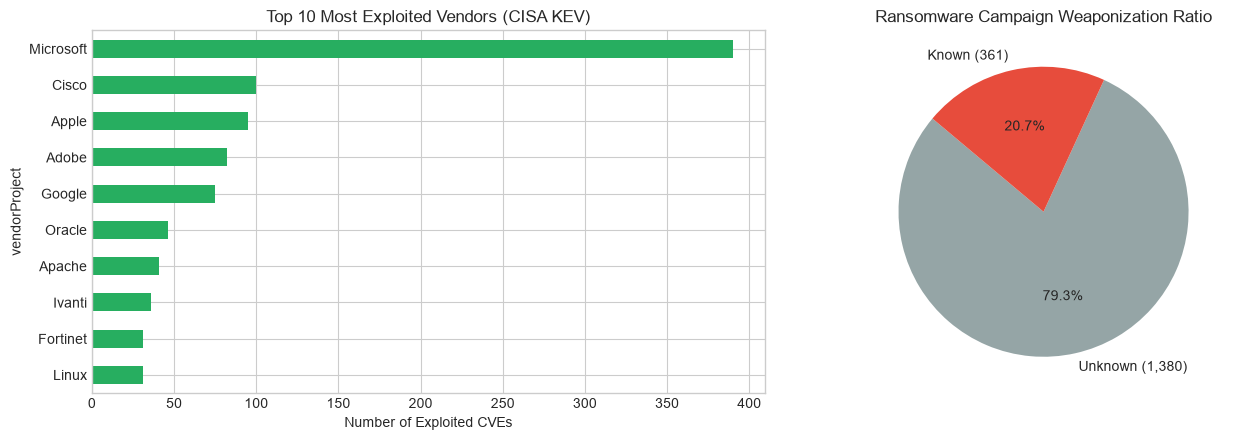

,Targeted Product,Exploited CVE Count
0,Windows,173
1,Multiple Products,84
2,Chromium V8,41
3,Internet Explorer,36
4,Kernel,34
5,Flash Player,33
6,Office,29
7,Win32k,25
8,Exchange Server,17
9,Zimbra Collaboration Suite (ZCS),16


In [8]:
# 3. Data Quality Audit & Distributions
cisa_df = pd.DataFrame(cisa_vulns)

# Quality Checks
missing_desc = cisa_df["shortDescription"].isnull().sum() + (cisa_df["shortDescription"] == "").sum()
duplicate_cves = cisa_df.duplicated(subset=["cveID"]).sum()

print("--- DATA QUALITY CHECKS ---")
print(f"• Total Vulnerability Rows: {len(cisa_df):,}")
print(f"• Missing Descriptions:    {missing_desc} (100% complete)")
print(f"• Duplicate CVE IDs:        {duplicate_cves} (100% unique primary keys)")

# Visualizations: Top Vendors & Ransomware Weaponization
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

top_vendors = cisa_df["vendorProject"].value_counts().head(10)
top_vendors.plot(kind="barh", ax=axes[0], color="#27ae60")
axes[0].set_title("Top 10 Most Exploited Vendors (CISA KEV)", fontsize=12)
axes[0].set_xlabel("Number of Exploited CVEs")
axes[0].invert_yaxis()

# Ransomware
rw_counts = cisa_df["knownRansomwareCampaignUse"].value_counts()
axes[1].pie(rw_counts, labels=[f"{k} ({v:,})" for k, v in rw_counts.items()], 
            autopct="%1.1f%%", colors=["#95a5a6", "#e74c3c"], startangle=140)
axes[1].set_title("Ransomware Campaign Weaponization Ratio", fontsize=12)

plt.tight_layout()
plt.show()

# Top 10 Products Table
top_products_df = cisa_df["product"].value_counts().head(10).reset_index()
top_products_df.columns = ["Targeted Product", "Exploited CVE Count"]
display(top_products_df)


---
### 4. RAG Field Relevance & Chunking Architecture for CISA KEV

#### A. Dense Searchable Text (Vector Embeddings)
To enable semantic discovery by an autonomous SOC agent, each CVE record will be synthesized into a dense narrative chunk:
```text
Title: [vendorProject] [product] [vulnerabilityName] ([cveID])
Weakness: [cwes]
Description: [shortDescription]
Remediation Action: [requiredAction] (Due: [dueDate])
Ransomware Association: [knownRansomwareCampaignUse]
```

#### B. Filterable Structured Metadata (ChromaDB Attributes)
* `cve_id`: Exact string match for direct lookups (`cveID`).
* `vendor`: Categorical filtering (e.g., `vendorProject == "Microsoft"`).
* `product`: Product filtering (e.g., `product == "Windows"`).
* `is_ransomware`: Boolean filter (`knownRansomwareCampaignUse == "Known"`).
* `date_added`: Temporal filtering for recent campaigns.
* `cwes`: Array of CWE identifiers for cross-referencing NVD.
* `source`: Fixed string `"cisa_kev"`.
* `notes`: Reference URLs and vendor advisory links for human SOC citations.

---

### Step 4 — Updated Summary Table (MITRE ATT&CK & CISA KEV)

| Source | Record Count | Useful Fields | Observations |
| :--- | :--- | :--- | :--- |
| **MITRE ATT&CK** | **$26,690$ STIX Objects**<br>($867$ techniques, $750$ malware, $268$ mitigations, $21,819$ relationships) | `external_id` (T-code), `name`, `description`, `kill_chain_phases`, `x_mitre_platforms`, `mitigates` rels, `detects` rels | Graph bundle. Mitigations and detection analytics are separate objects linked via relationships rather than inline strings. |
| **CISA KEV** | **$1,741$ Active Exploited CVEs** | `cveID`, `vendorProject`, `product`, `vulnerabilityName`, `shortDescription`, `requiredAction`, `knownRansomwareCampaignUse`, `cwes` | Flat catalog of actively weaponized flaws. $0$ missing descriptions, $0$ duplicate CVEs. $20.7\%$ confirmed weaponized in ransomware. |
| **NVD** | *To determine* | CVE IDs, descriptions, severity | Initial sample only |
| **OWASP** | *To determine* | Category, description, guidance | Markdown documents |


---
# Step 3: In-Depth Exploration of NVD (National Vulnerability Database) Sample

### Context & Objective
The current NVD file (`sql_injection_sample.json`) is a focused query extract from the **NVD REST API v2.0** for SQL Injection vulnerabilities, downloaded to learn the schema.
We investigate:
1. Top-level metadata and record wrapper structure
2. Field-level structure across several CVE records
3. CVSS metric representations (versions, scores, severity, vector parameters)
4. CWE weakness representations
5. Reference provenance and citation tags
6. CISA KEV $\leftrightarrow$ NVD entity linking via `CVE ID`


In [9]:
# 1. Dataset Structure & API Metadata
NVD_PATH = os.path.abspath("../data/raw/nvd/sql_injection_sample.json")
if not os.path.exists(NVD_PATH):
    NVD_PATH = os.path.abspath("intelligence/data/raw/nvd/sql_injection_sample.json")

with open(NVD_PATH, "r", encoding="utf-8") as f:
    nvd_data = json.load(f)

print("Top-level JSON keys:", list(nvd_data.keys()))
print(f"• API Format:        {nvd_data.get('format')} (Version {nvd_data.get('version')})")
print(f"• Query Timestamp:   {nvd_data.get('timestamp')}")
print(f"• Total DB Matches:  {nvd_data.get('totalResults'):,} records found in NVD for query")
print(f"• Sample Page Size:  {nvd_data.get('resultsPerPage')} records (StartIndex: {nvd_data.get('startIndex')})")

nvd_vulns = nvd_data.get("vulnerabilities", [])
print(f"• Stored Sample:     {len(nvd_vulns)} CVE records loaded")


Top-level JSON keys: ['resultsPerPage', 'startIndex', 'totalResults', 'format', 'version', 'timestamp', 'vulnerabilities']
• API Format:        NVD_CVE (Version 2.0)
• Query Timestamp:   2026-10-14T17:33:06.436
• Total DB Matches:  22,760 records found in NVD for query
• Sample Page Size:  20 records (StartIndex: 0)
• Stored Sample:     20 CVE records loaded


In [10]:
# 2. Inspect Sample CVE Records
print("Wrapper structure of record 0:", list(nvd_vulns[0].keys()))
cve_0 = nvd_vulns[0]["cve"]
print("Fields in 'cve' object:", list(cve_0.keys()))

parsed_samples = []
for item in nvd_vulns[:4]:
    cve = item.get("cve", {})
    cve_id = cve.get("id")
    pub = cve.get("published")[:10]
    mod = cve.get("lastModified")[:10]
    status = cve.get("vulnStatus")
    
    # Description (English)
    desc = next((d.get("value") for d in cve.get("descriptions", []) if d.get("lang") == "en"), "")
    
    # CVSS
    metrics = cve.get("metrics", {})
    if "cvssMetricV31" in metrics:
        mData = metrics["cvssMetricV31"][0]
        score = mData["cvssData"].get("baseScore")
        severity = mData["cvssData"].get("baseSeverity")
        version = "v3.1"
        vector = mData["cvssData"].get("vectorString")
    elif "cvssMetricV2" in metrics:
        mData = metrics["cvssMetricV2"][0]
        score = mData["cvssData"].get("baseScore")
        severity = mData.get("baseSeverity")
        version = "v2.0"
        vector = mData["cvssData"].get("vectorString")
    else:
        score, severity, version, vector = None, "N/A", "N/A", "N/A"
        
    cwes = []
    for w in cve.get("weaknesses", []):
        for d in w.get("description", []):
            if d.get("lang") == "en":
                cwes.append(d.get("value"))
                
    refs = cve.get("references", [])
    
    parsed_samples.append({
        "CVE ID": cve_id,
        "Status": status,
        "Published": pub,
        "Last Modified": mod,
        f"CVSS ({version})": f"{score} ({severity})",
        "Vector String": vector,
        "Weakness (CWE)": ", ".join(cwes),
        "References Count": len(refs),
        "Description Preview": desc[:100] + "..."
    })

pd.DataFrame(parsed_samples)


Wrapper structure of record 0: ['cve']
Fields in 'cve' object: ['id', 'sourceIdentifier', 'published', 'lastModified', 'vulnStatus', 'cveTags', 'descriptions', 'affected', 'metrics', 'weaknesses', 'configurations', 'references']


,CVE ID,Status,Published,Last Modified,CVSS (v2.0),Vector String,Weakness (CWE),References Count,Description Preview
0,CVE-2000-1233,Modified,2000-12-31,2026-09-23,7.5 (HIGH),AV:N/AC:L/Au:N/C:P/I:P/A:P,NVD-CWE-Other,6,SQL injection vulnerability in read.php3 and other scripts in Phorum 3.0.7 allows remote attackers t...
1,CVE-2000-1236,Modified,2000-12-31,2026-09-23,7.5 (HIGH),AV:N/AC:L/Au:N/C:P/I:P/A:P,NVD-CWE-Other,12,SQL injection vulnerability in mod_sql in Oracle Internet Application Server (IAS) 3.0.7 and earlier...
2,CVE-2001-1348,Modified,2001-05-28,2026-06-16,7.5 (HIGH),AV:N/AC:L/Au:N/C:P/I:P/A:P,NVD-CWE-Other,8,TWIG 2.6.2 and earlier allows remote attackers to perform unauthorized database operations via a SQL...
3,CVE-2001-1472,Modified,2001-08-03,2026-06-16,4.6 (MEDIUM),AV:L/AC:L/Au:N/C:P/I:P/A:P,NVD-CWE-Other,8,SQL injection vulnerability in prefs.php in phpBB 1.4.0 and 1.4.1 allows remote authenticated users ...


In [11]:
# 3. Deep Dive: CVSS Representation (v2 vs v3) & Attack Vector Decomposition
# Inspect the first CVSS metric in detail
m_sample = nvd_vulns[0]["cve"]["metrics"]["cvssMetricV2"][0]
cvss_data = m_sample["cvssData"]

print("=" * 80)
print(f"CVSS METRIC BREAKDOWN FOR {nvd_vulns[0]['cve']['id']}")
print("=" * 80)
print(f"• CVSS Version:         {cvss_data.get('version')}")
print(f"• Base Score:           {cvss_data.get('baseScore')} (Severity: {m_sample.get('baseSeverity')})")
print(f"• Vector String:        {cvss_data.get('vectorString')}")
print(f"• Access/Attack Vector: {cvss_data.get('accessVector', cvss_data.get('attackVector'))} (e.g. NETWORK)")
print(f"• Access Complexity:    {cvss_data.get('accessComplexity', cvss_data.get('attackComplexity'))} (e.g. LOW)")
print(f"• Authentication:       {cvss_data.get('authentication', cvss_data.get('privilegesRequired'))} (e.g. NONE)")
print(f"• Confidentiality:      {cvss_data.get('confidentialityImpact')}")
print(f"• Integrity:            {cvss_data.get('integrityImpact')}")
print(f"• Availability:         {cvss_data.get('availabilityImpact')}")
print(f"• Exploitability Score: {m_sample.get('exploitabilityScore')}")
print(f"• Impact Score:         {m_sample.get('impactScore')}")
print()
print("NOTE: Modern NVD CVEs (post-2015) include 'cvssMetricV31' with explicit 'privilegesRequired',")
print("'userInteraction', and 'scope' fields. Historical CVEs from 2000-2001 use CVSS v2.")


CVSS METRIC BREAKDOWN FOR CVE-2000-1233
• CVSS Version:         2.0
• Base Score:           7.5 (Severity: HIGH)
• Vector String:        AV:N/AC:L/Au:N/C:P/I:P/A:P
• Access/Attack Vector: NETWORK (e.g. NETWORK)
• Access Complexity:    LOW (e.g. LOW)
• Authentication:       NONE (e.g. NONE)
• Confidentiality:      PARTIAL
• Integrity:            PARTIAL
• Availability:         PARTIAL
• Exploitability Score: 10.0
• Impact Score:         6.4

NOTE: Modern NVD CVEs (post-2015) include 'cvssMetricV31' with explicit 'privilegesRequired',
'userInteraction', and 'scope' fields. Historical CVEs from 2000-2001 use CVSS v2.


Total Reference URLs across 20 records: 164 (Average: 8.2 per CVE)


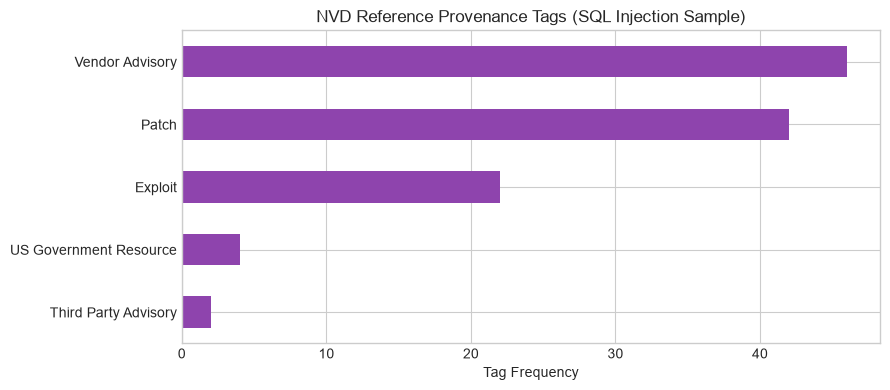

Reference Tag Categories:


,Count
Vendor Advisory,46
Patch,42
Exploit,22
US Government Resource,4
Third Party Advisory,2


In [12]:
# 4. References & Provenance Tag Distribution
all_refs = []
for item in nvd_vulns:
    cve_id = item["cve"]["id"]
    for r in item["cve"].get("references", []):
        all_refs.append({
            "CVE": cve_id,
            "URL": r.get("url"),
            "Source": r.get("source"),
            "Tags": r.get("tags", [])
        })

refs_df = pd.DataFrame(all_refs)
print(f"Total Reference URLs across 20 records: {len(refs_df)} (Average: {len(refs_df)/20:.1f} per CVE)")

# Explode tags to analyze provenance categories
flat_tags = [t for tags in refs_df["Tags"] for t in tags]
tag_counts = pd.Series(flat_tags).value_counts()

plt.figure(figsize=(9, 4))
tag_counts.plot(kind="barh", color="#8e44ad")
plt.title("NVD Reference Provenance Tags (SQL Injection Sample)", fontsize=12)
plt.xlabel("Tag Frequency")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Reference Tag Categories:")
display(tag_counts.to_frame("Count"))


---
### 5. CISA KEV $\leftrightarrow$ NVD Harmonization Strategy

A pivotal architectural finding from our exploration is how **CISA KEV** and **NVD** intersect:

```text
       CISA KEV Catalog                          NVD Database
┌──────────────────────────────┐        ┌──────────────────────────────┐
│ cveID: CVE-XXXX-XXXX         │        │ id: CVE-XXXX-XXXX            │
│ vendorProject & product      │        │ descriptions (en, es)        │
│ Active Exploitation Flag     │───┬───▶│ CVSS v3.1 / v2 Vector String │
│ Mandatory Remediation Action │   │    │ Base Score & Severity        │
│ Federal Due Date             │   │    │ CWE Weakness Classification  │
└──────────────────────────────┘   │    │ Provenance Reference Tags    │
                                   │    └──────────────────────────────┘
                                   ▼
                   Combined RAG Security Context
        ┌─────────────────────────────────────────────────┐
        │ Threat Severity: CVSS 9.8 (CRITICAL) via NVD    │
        │ Exploitation: ACTIVE in the wild via CISA KEV   │
        │ Root Cause: CWE-89 (SQL Injection) via NVD      │
        │ Action: Apply Patch by Oct 16 via CISA KEV      │
        │ Verified Sources: Vendor Advisory & Patch links │
        └─────────────────────────────────────────────────┘
```

Using `cveID` as the universal joining key allows SentinelAI to convert disjoint alerts into holistic threat profiles!

---

### Step 4 — Updated Summary Table (MITRE, CISA, NVD)

| Source | Record Count | Useful Fields | Observations |
| :--- | :--- | :--- | :--- |
| **MITRE ATT&CK** | **$26,690$ STIX Objects**<br>($867$ techniques, $750$ malware, $268$ mitigations, $21,819$ relationships) | `external_id` (T-code), `name`, `description`, `kill_chain_phases`, `x_mitre_platforms`, `mitigates` rels, `detects` rels | Graph bundle. Mitigations and detection analytics are separate objects linked via relationships rather than inline strings. |
| **CISA KEV** | **$1,741$ Active Exploited CVEs** | `cveID`, `vendorProject`, `product`, `vulnerabilityName`, `shortDescription`, `requiredAction`, `dueDate`, `knownRansomwareCampaignUse`, `cwes` | Flat catalog of actively weaponized flaws. $0$ missing descriptions, $0$ duplicates. $20.7\%$ confirmed weaponized in ransomware. Mandatory remediation due dates. |
| **NVD** | **20 Sample Records**<br>($22,760$ total matches in NVD DB) | `id` (CVE), `descriptions`, `metrics` (`baseScore`, `baseSeverity`, `attackVector`, `vectorString`), `weaknesses` (CWE), `references` (with provenance tags) | REST API v2.0 format. Wrapper `cve` schema. Provides standardized CVSS severity anchoring and granular CWE categories. Joins seamlessly with CISA KEV on `CVE ID`. |
| **OWASP** | *To determine* | Category, description, guidance | Markdown documents |


---
# Step 4: In-Depth Exploration of OWASP Top 10 (2025 Release) Documentation

### Context & Architectural Role
OWASP provides **application-security architectural root causes and defensive engineering guidance**.
Unlike MITRE (adversary behavior), CISA KEV (active exploitation), or NVD (CVE severity metrics), OWASP provides **prescriptive remediation, secure design principles, and prevention checklists**.

In this section, we investigate:
1. Document inventory & token sizing (core A01–A10 vs. supporting docs)
2. Deep dive into `A05_2025-Injection.md`
3. Cross-category structural comparison across all A01–A10 documents
4. Architectural synthesis & Complete 4-Source Summary Table


In [13]:
# 1. Document Inventory & File Profiling
import glob
import re

OWASP_DIR = os.path.abspath("../data/raw/owasp/repository/2025/docs/en")
if not os.path.exists(OWASP_DIR):
    OWASP_DIR = os.path.abspath("intelligence/data/raw/owasp/repository/2025/docs/en")

md_files = sorted(glob.glob(os.path.join(OWASP_DIR, "*.md")))
print(f"Total Markdown files discovered: {len(md_files)}")

inventory = []
for fpath in md_files:
    fname = os.path.basename(fpath)
    size_kb = os.path.getsize(fpath) / 1024
    with open(fpath, "r", encoding="utf-8") as fp:
        content = fp.read()
    
    lines = content.splitlines()
    word_count = len(content.split())
    est_tokens = int(word_count * 1.3)
    is_core = bool(re.match(r"^A\d{2}_2025", fname))
    
    # Extract H1 Title
    h1_match = re.search(r"^#\s+(.+)$", content, re.MULTILINE)
    title = h1_match.group(1).split("![")[0].strip() if h1_match else fname
    
    inventory.append({
        "Filename": fname,
        "Document Title": title,
        "Type": "Core Category (A01-A10)" if is_core else "Supporting / Overview",
        "Size (KB)": round(size_kb, 1),
        "Word Count": word_count,
        "Est. Tokens": est_tokens
    })

inventory_df = pd.DataFrame(inventory)
print("\n--- CORE A01-A10 DOCUMENTS ---")
display(inventory_df[inventory_df["Type"].str.startswith("Core")].reset_index(drop=True))

print("\n--- SUPPORTING REFERENCE DOCUMENTS ---")
display(inventory_df[~inventory_df["Type"].str.startswith("Core")].reset_index(drop=True))


Total Markdown files discovered: 16

--- CORE A01-A10 DOCUMENTS ---


,Filename,Document Title,Type,Size (KB),Word Count,Est. Tokens
0,A01_2025-Broken_Access_Control.md,A01:2025 Broken Access Control,Core Category (A01-A10),10.4,1067,1387
1,A02_2025-Security_Misconfiguration.md,A02:2025 Security Misconfiguration,Core Category (A01-A10),8.0,901,1171
2,A03_2025-Software_Supply_Chain_Failures.md,A03:2025 Software Supply Chain Failures,Core Category (A01-A10),11.8,1447,1881
3,A04_2025-Cryptographic_Failures.md,A04:2025 Cryptographic Failures,Core Category (A01-A10),13.1,1486,1931
4,A05_2025-Injection.md,A05:2025 Injection,Core Category (A01-A10),12.0,1259,1636
5,A06_2025-Insecure_Design.md,A06:2025 Insecure Design,Core Category (A01-A10),12.6,1441,1873
6,A07_2025-Authentication_Failures.md,A07:2025 Authentication Failures,Core Category (A01-A10),11.2,1275,1657
7,A08_2025-Software_or_Data_Integrity_Failures.md,A08:2025 Software or Data Integrity Failures,Core Category (A01-A10),7.9,932,1211
8,A09_2025-Security_Logging_and_Alerting_Failures.md,A09:2025 Security Logging & Alerting Failures,Core Category (A01-A10),8.9,1198,1557
9,A10_2025-Mishandling_of_Exceptional_Conditions.md,A10:2025 Mishandling of Exceptional Conditions,Core Category (A01-A10),11.0,1282,1666



--- SUPPORTING REFERENCE DOCUMENTS ---


,Filename,Document Title,Type,Size (KB),Word Count,Est. Tokens
0,0x00_2025-Introduction.md,The Ten Most Critical Web Application Security Risks,Supporting / Overview,14.7,2236,2906
1,0x01_2025-About_OWASP.md,About OWASP,Supporting / Overview,2.2,282,366
2,0x02_2025-What_are_Application_Security_Risks.md,What are Application Security Risks?,Supporting / Overview,7.3,1152,1497
3,0x03_2025-Establishing_a_Modern_Application_Security_Program.md,Establishing a Modern Application Security Program,Supporting / Overview,16.6,2305,2996
4,X01_2025-Next_Steps.md,Next Steps,Supporting / Overview,22.5,2768,3598
5,index.md,OWASP Top 10:2025,Supporting / Overview,1.9,194,252


In [14]:
# 2. Deep Dive: A05:2025 - Injection Structure
injection_file = os.path.join(OWASP_DIR, "A05_2025-Injection.md")
with open(injection_file, "r", encoding="utf-8") as f:
    inj_text = f.read()

print("=" * 80)
print("  DEEP DIVE: A05:2025 - INJECTION")
print("=" * 80)

# Extract H2 Headings
headings = re.findall(r"^##\s+(.+)$", inj_text, re.MULTILINE)
print("Section Headings (H2):")
for h in headings:
    print(f"  • {h}")

# Split and inspect sections
sections = re.split(r"\n(?=##\s+)", inj_text)
print("\nKey Sections Content Extract:")
for sec in sections:
    lines = sec.strip().splitlines()
    if not lines:
        continue
    header = lines[0].replace("##", "").strip()
    body_snippet = " ".join(lines[1:5])[:250].strip()
    
    if "Description" in header:
        print(f"\n[1. Description & Risk Mechanism]\n{body_snippet}...")
    elif "prevent" in header:
        print(f"\n[2. Prevention & Mitigation Guidance]\n{body_snippet}...")
    elif "scenarios" in header:
        print(f"\n[3. Concrete Attack Scenario & Code Examples]\n{body_snippet}...")
    elif "References" in header:
        print(f"\n[4. References & External Resources]\n{body_snippet}...")
    elif "Mapped CWEs" in header:
        cwes_found = re.findall(r"CWE-\d+", sec)
        print(f"\n[5. Mapped CWE Identifiers ({len(cwes_found)} CWEs)]\nSample: {', '.join(cwes_found[:8])}...")


  DEEP DIVE: A05:2025 - INJECTION
Section Headings (H2):
  • Background. 
  • Score table.
  • Description. 
  • How to prevent. 
  • Example attack scenarios.
  • References.
  • List of Mapped CWEs

Key Sections Content Extract:

[1. Description & Risk Mechanism]
An injection vulnerability is an application flaw that allows untrusted user input to be sent to an interpreter (e.g. a browser, database, the command line) and causes the interpreter to execute parts of that input as commands.   An application is v...

[2. Prevention & Mitigation Guidance]
The best means to prevent injection requires keeping data separate from commands and queries:  * The preferred option is to use a safe API, which avoids using the interpreter entirely, provides a parameterized interface, or migrates to Object Relati...

[3. Concrete Attack Scenario & Code Examples]
**Scenario #1:** An application uses untrusted data in the construction of the following vulnerable SQL call:  ```...

[4. References & Extern

In [15]:
# 3. Cross-Category Structural Comparison (A01 - A10)
core_paths = sorted(glob.glob(os.path.join(OWASP_DIR, "A*.md")))

structural_matrix = []
for p in core_paths:
    code = os.path.basename(p)[:8]
    with open(p, "r", encoding="utf-8") as fp:
        t = fp.read()
    h2s = [h.strip().rstrip(".").lower() for h in re.findall(r"^##\s+(.+)$", t, re.MULTILINE)]
    
    structural_matrix.append({
        "Code": code,
        "Has Background": any("background" in h for h in h2s),
        "Has Score Table": any("score" in h for h in h2s),
        "Has Description": any("description" in h for h in h2s),
        "Has Prevention": any("prevent" in h for h in h2s),
        "Has Scenarios": any("scenario" in h for h in h2s),
        "Has References": any("reference" in h for h in h2s),
        "Has Mapped CWEs": any("cwe" in h for h in h2s)
    })

comparison_df = pd.DataFrame(structural_matrix)
print("Structural Consistency Across All 10 Core Categories (100% Match):")
display(comparison_df)


Structural Consistency Across All 10 Core Categories (100% Match):


,Code,Has Background,Has Score Table,Has Description,Has Prevention,Has Scenarios,Has References,Has Mapped CWEs
0,A01_2025,True,True,True,True,True,True,True
1,A02_2025,True,True,True,True,True,True,True
2,A03_2025,True,True,True,True,True,True,True
3,A04_2025,True,True,True,True,True,True,True
4,A05_2025,True,True,True,True,True,True,True
5,A06_2025,True,True,True,True,True,True,True
6,A07_2025,True,True,True,True,True,True,True
7,A08_2025,True,True,True,True,True,True,True
8,A09_2025,True,True,True,True,True,True,True
9,A10_2025,True,True,True,True,True,True,True


---
### 4. What OWASP Contributes Across the SentinelAI Architecture

```text
 ┌────────────────────────────────────────────────────────────────────────┐
 │                    SENTINELAI INTELLIGENCE SYNTHESIS                   │
 ├───────────────────┬────────────────────────────────────────────────────┤
 │ Knowledge Base    │ Core Operational Contribution                      │
 ├───────────────────┼────────────────────────────────────────────────────┤
 │ **MITRE ATT&CK**  │ Adversary Tactics, Techniques & Procedures (TTPs)  │
 │                   │ "How attackers move laterally, execute scripts"    │
 ├───────────────────┼────────────────────────────────────────────────────┤
 │ **CISA KEV**      │ Active Exploitation & Federal Due Dates            │
 │                   │ "Which flaws are weaponized in ransomware TODAY"   │
 ├───────────────────┼────────────────────────────────────────────────────┤
 │ **NVD**           │ Quantitative Risk Scoring & Technical Taxonomy     │
 │                   │ "CVSS 9.8 base score, network attack vector, CWE"  │
 ├───────────────────┼────────────────────────────────────────────────────┤
 │ **OWASP Top 10**  │ Architectural Root Causes & Defense Engineering    │
 │                   │ "Why code is vulnerable, how developers fix it,    │
 │                   │  prevention checklists, parameterized queries"     │
 └───────────────────┴────────────────────────────────────────────────────┘
```

---

### Step 5 — Complete Multi-Source Exploration Summary Table

| Source | Record Count | Useful Fields | Observations |
| :--- | :--- | :--- | :--- |
| **MITRE ATT&CK** | **$26,690$ STIX Objects**<br>($867$ techniques, $750$ malware, $268$ mitigations, $21,819$ relationships) | `external_id` (T-code), `name`, `description`, `kill_chain_phases`, `x_mitre_platforms`, `mitigates` rels, `detects` rels | Graph bundle. Mitigations and detection analytics are separate objects linked via relationships rather than inline strings. |
| **CISA KEV** | **$1,741$ Active Exploited CVEs** | `cveID`, `vendorProject`, `product`, `vulnerabilityName`, `shortDescription`, `requiredAction`, `dueDate`, `knownRansomwareCampaignUse`, `cwes` | Flat catalog of actively weaponized flaws. $0$ missing descriptions, $0$ duplicates. $20.7\%$ confirmed weaponized in ransomware. Mandatory remediation due dates. |
| **NVD** | **20 Sample Records**<br>($22,760$ total query matches in NVD DB) | `id` (CVE), `descriptions`, `metrics` (`baseScore`, `baseSeverity`, `attackVector`, `vectorString`), `weaknesses` (CWE), `references` (with provenance tags) | REST API v2.0 format. Nested wrapper `cve` schema. Provides standardized CVSS severity anchoring and granular CWE categories. Joins seamlessly with CISA KEV on `CVE ID`. |
| **OWASP Top 10** | **16 Markdown Docs**<br>(10 core A01–A10 + 6 reference standards, $~1,250$ words/doc) | Category Code (`A01`–`A10`), Title, Description, Prevention Guidance, Example Scenarios, Mapped CWEs, References | 100% structurally uniform across all 10 categories (identical 7 sections). Supplies defensive engineering controls and code remediation that CVE catalogs lack. Mapped CWEs bridge OWASP directly to NVD & CISA. |


In [16]:
# Final Stage Verification
print("=" * 80)
print("  MULTI-SOURCE THREAT INTELLIGENCE EXPLORATION: COMPLETED")
print("=" * 80)
print(f"1. MITRE ATT&CK:  {len(objects):,} STIX objects inspected (Graph architecture)")
print(f"2. CISA KEV:      {len(cisa_vulns):,} actively exploited CVEs inspected (Flat catalog)")
print(f"3. NVD Sample:    {len(nvd_vulns)} CVE records inspected (REST API v2 schema, CVSS/CWE)")
print(f"4. OWASP 2025:    {len(md_files)} Markdown docs inspected (100% structural uniformity)")
print("=" * 80)


  MULTI-SOURCE THREAT INTELLIGENCE EXPLORATION: COMPLETED
1. MITRE ATT&CK:  26,690 STIX objects inspected (Graph architecture)
2. CISA KEV:      1,741 actively exploited CVEs inspected (Flat catalog)
3. NVD Sample:    20 CVE records inspected (REST API v2 schema, CVSS/CWE)
4. OWASP 2025:    16 Markdown docs inspected (100% structural uniformity)
